In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import pandas as pd
from sklearn.model_selection import train_test_split


In [2]:
data={
    "Study_Hours":[2,3,4,5,6,7,8,9],
    "Study_Hours_week":[14,21,28,35,42,49,56,63],
    "Attendence": [60,65,70,75,80,85,90,95],
    "Assignment_score":[50,55,58,65,70,74,80,88],
    "Final_marks":[42,48,54,61,67,73,81,89]
}

In [3]:
df=pd.DataFrame(data)
df

,Study_Hours,Study_Hours_week,Attendence,Assignment_score,Final_marks
0,2,14,60,50,42
1,3,21,65,55,48
2,4,28,70,58,54
3,5,35,75,65,61
4,6,42,80,70,67
5,7,49,85,74,73
6,8,56,90,80,81
7,9,63,95,88,89


In [4]:
x=df[["Study_Hours","Study_Hours_week","Attendence","Assignment_score"]]
y=df["Final_marks"]

In [5]:
model=LinearRegression()
model.fit(x,y)
print("Intercept",model.intercept_)

Intercept -6.852852852852834


In [6]:
coefficient_table=pd.DataFrame({
    "feature":x.columns,
    "coefficient":model.coef_
})


In [7]:
print(coefficient_table)

            feature  coefficient
0       Study_Hours     0.045556
1  Study_Hours_week     0.318889
2        Attendence     0.227778
3  Assignment_score     0.608108


**convert df to csv**

In [9]:
df.to_csv("data.csv",index=False)

In [10]:
df_2 = pd.read_csv("data.csv")
df_2

,Study_Hours,Study_Hours_week,Attendence,Assignment_score,Final_marks
0,2,14,60,50,42
1,3,21,65,55,48
2,4,28,70,58,54
3,5,35,75,65,61
4,6,42,80,70,67
5,7,49,85,74,73
6,8,56,90,80,81
7,9,63,95,88,89


In [12]:
X = df_2.drop("Final_marks",axis=1)
y = df_2["Final_marks"]
model = LinearRegression()
model.fit(X,y)

LinearRegression()

In [13]:
print("Intercept",model.intercept_)
coefficient_table = pd.DataFrame({
    "Features": X.columns,
    "Coefficients": model.coef_
})
coefficient_table

Intercept -6.852852852852834


,Features,Coefficients
0,Study_Hours,0.045556
1,Study_Hours_week,0.318889
2,Attendence,0.227778
3,Assignment_score,0.608108


In [20]:

new_data = {
    "Study_Hours": [6],
    "Study_Hours_week":[x * 7 for x in [6]],
    "Attendence": [82],
    "Assignment_score":[72]
}

In [21]:
print("Predicted value",model.predict(pd.DataFrame(new_data)))

Predicted value [69.27537538]


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model_split = LinearRegression()
model_split.fit(X_train, y_train)

LinearRegression()

In [24]:
print("Intercept",model_split.intercept_)
coefficient_table = pd.DataFrame({
    "Features": X.columns,
    "Coefficients": model_split.coef_
})
coefficient_table

Intercept -5.246666666666698


,Features,Coefficients
0,Study_Hours,0.050933
1,Study_Hours_week,0.356533
2,Attendence,0.254667
3,Assignment_score,0.533333


In [25]:
y_pred = model_split.predict(X_test)
y_pred

array([48.28      , 73.69333333])

In [26]:
print("Predicted value with split",model_split.predict(pd.DataFrame(new_data)))

Predicted value with split [69.316]


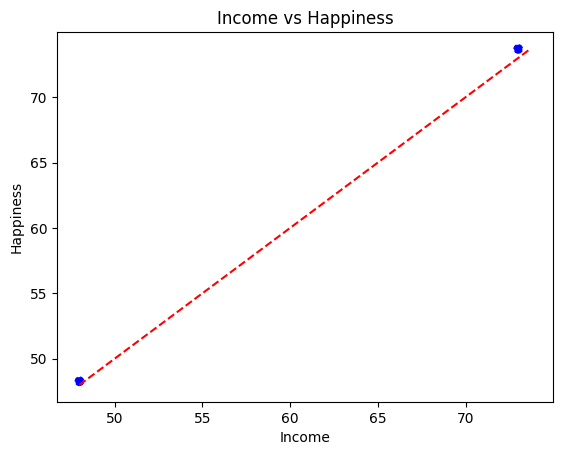

In [27]:
plt.scatter(y_test,y_pred,color="blue",linestyle="--")
minimum = min(min(y_test),min(y_pred))
maximum = max(max(y_test),max(y_pred))
plt.plot([minimum,maximum],[minimum,maximum],color="red",linestyle="--")
plt.xlabel("Income")
plt.ylabel("Happiness")
plt.title("Income vs Happiness")
plt.show()